# Correlation Practical (ABA Unit 1, Practical 7)

**Aim:** conduct correlation analysis to identify relationships among business variables (Sahyadri Mart daily sales, synthetic).

Run the cells in order (Runtime → Run all). Nothing to install. The note `correlation-practical` on Sutra explains every step.

In [1]:
# Step 1. Load the data
import pandas as pd
import numpy as np

url = ("https://raw.githubusercontent.com/Prathameshv07/ai-ds-notes/main/"
       "content/assets/data/sahyadri-mart-sales.csv")
df = pd.read_csv(url, parse_dates=["date"])
print("Rows, columns:", df.shape)

Rows, columns: (8772, 16)


In [2]:
# Step 2. Pearson's r by its formula: footfall vs revenue
x, y = df["footfall"], df["revenue_inr"]
cov_xy = ((x - x.mean()) * (y - y.mean())).sum() / (len(x) - 1)
r = cov_xy / (x.std() * y.std())
print(f"Covariance   : {cov_xy:,.0f}  (visitors x Rs)")
print(f"r by formula : {r:.4f}")
print(f"r by pandas  : {x.corr(y):.4f}")

Covariance   : 186,656,844  (visitors x Rs)
r by formula : 0.9607
r by pandas  : 0.9607


In [3]:
# Step 3. Change the unit of revenue to Rs lakh: covariance changes, r does not
y_lakh = y / 1e5
print(f"Covariance (revenue in Rs lakh): {x.cov(y_lakh):,.2f}")
print(f"r          (revenue in Rs lakh): {x.corr(y_lakh):.4f}")

Covariance (revenue in Rs lakh): 1,866.57
r          (revenue in Rs lakh): 0.9607


In [4]:
# Step 4. Correlation matrix of the main business variables
cols = {"store_area_sqft": "area", "ad_spend_inr": "ad_spend", "discount_pct": "discount",
        "rainfall_mm": "rain", "footfall": "footfall", "transactions": "bills", "revenue_inr": "revenue"}
print(df[list(cols)].rename(columns=cols).corr().round(2).to_string())

          area  ad_spend  discount  rain  footfall  bills  revenue
area      1.00      0.62     -0.01  0.00      0.81   0.79     0.89
ad_spend  0.62      1.00      0.02  0.00      0.59   0.57     0.61
discount -0.01      0.02      1.00 -0.01      0.14   0.21     0.09
rain      0.00      0.00     -0.01  1.00     -0.05  -0.05    -0.02
footfall  0.81      0.59      0.14 -0.05      1.00   0.99     0.96
bills     0.79      0.57      0.21 -0.05      0.99   1.00     0.96
revenue   0.89      0.61      0.09 -0.02      0.96   0.96     1.00


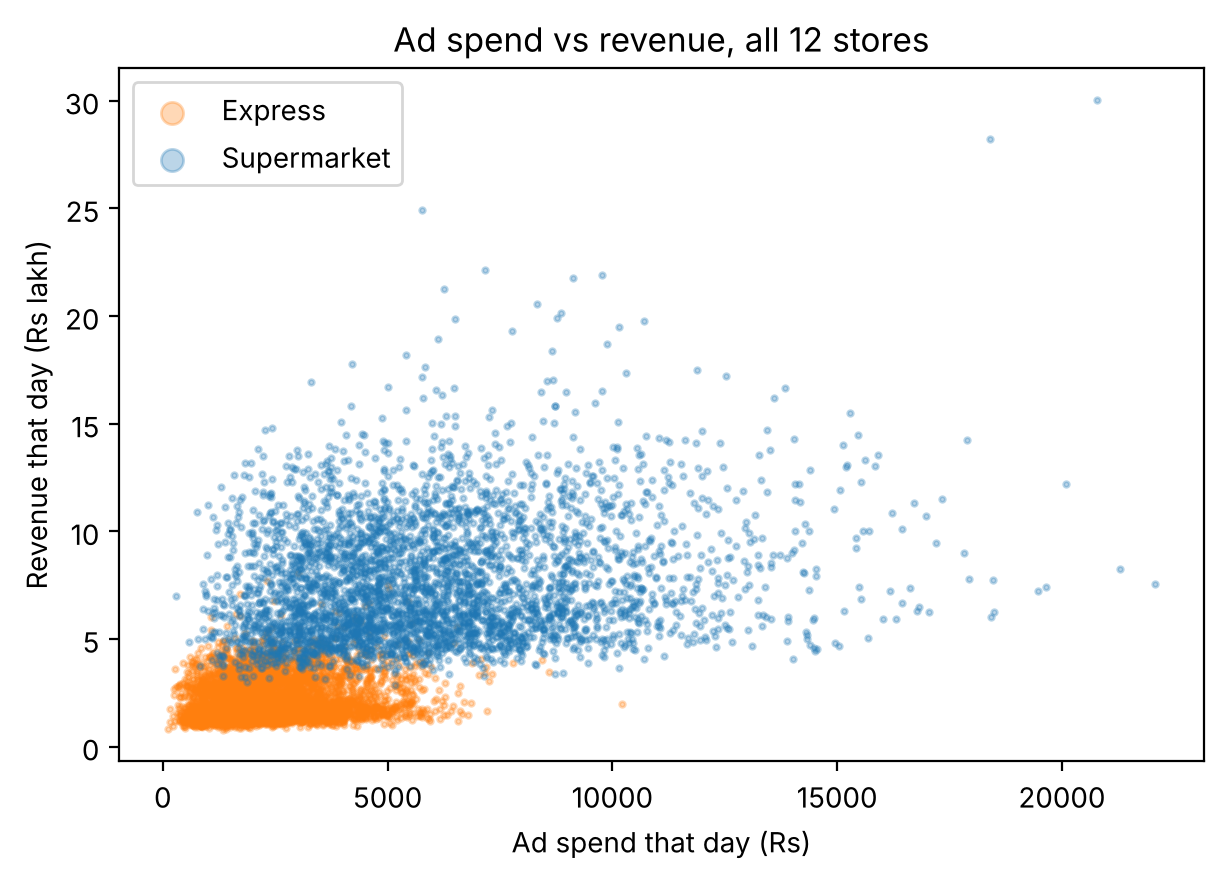

In [5]:
# Step 5. Scatter plot: ad spend vs revenue, coloured by store type
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4.5))
for t, colour in [("Express", "tab:orange"), ("Supermarket", "tab:blue")]:
    g = df[df["store_type"] == t]
    ax.scatter(g["ad_spend_inr"], g["revenue_inr"] / 1e5, s=4, alpha=0.3, color=colour, label=t)
ax.set_xlabel("Ad spend that day (Rs)")
ax.set_ylabel("Revenue that day (Rs lakh)")
ax.set_title("Ad spend vs revenue, all 12 stores")
ax.legend(markerscale=4)
plt.show()

In [6]:
# Step 6. Ad spend vs revenue: whole chain, each store type, each store
print(f"Whole chain : r = {df['ad_spend_inr'].corr(df['revenue_inr']):.2f}")
for t, g in df.groupby("store_type"):
    print(f"{t:12}: r = {g['ad_spend_inr'].corr(g['revenue_inr']):.2f}")
per_store = df.groupby("store_id").apply(
    lambda g: g["ad_spend_inr"].corr(g["revenue_inr"]), include_groups=False)
print("\nWithin each store:")
print(per_store.round(2).to_string())
print(f"Median within-store r: {per_store.median():.2f}")

Whole chain : r = 0.61
Express     : r = 0.16
Supermarket : r = 0.20

Within each store:
store_id
S01    0.25
S02    0.21
S03    0.29
S04    0.34
S05    0.25
S06    0.23
S07    0.33
S08    0.27
S09    0.26
S10    0.26
S11    0.33
S12    0.31
Median within-store r: 0.27


In [7]:
# Step 7. The hidden third variable: store size
stores = df.groupby(["store_id", "store_type"])[["store_area_sqft", "ad_spend_inr", "revenue_inr"]].mean()
print(stores.round(0).astype(int).to_string())
print(f"\nAcross the 12 stores: r(area, ad spend) = {stores['store_area_sqft'].corr(stores['ad_spend_inr']):.2f}, "
      f"r(area, revenue) = {stores['store_area_sqft'].corr(stores['revenue_inr']):.2f}")

                      store_area_sqft  ad_spend_inr  revenue_inr
store_id store_type                                             
S01      Supermarket             9000          6091      1076818
S02      Express                 2800          2498       347644
S03      Express                 2200          2407       158478
S04      Supermarket             8500          5984       953601
S05      Express                 3000          2372       320562
S06      Express                 2500          2379       191858
S07      Supermarket             7000          6111       597131
S08      Express                 2300          2375       159013
S09      Supermarket             6500          5905       538047
S10      Express                 2200          2352       144172
S11      Supermarket             7500          6133       671530
S12      Express                 2400          2292       169665

Across the 12 stores: r(area, ad spend) = 0.97, r(area, revenue) = 0.97
